In [3]:
# -------------------------------------------
# 1. Load the passing data
# -------------------------------------------

import pandas as pd
from pathlib import Path

xpass_df = pd.read_csv(Path.cwd().parent / "data/cleaned/xPass.csv")
xt_df = pd.read_csv(Path.cwd().parent / "data/cleaned/xT.csv")

In [9]:
# -------------------------------------------
# 2. Aggregate player passes in each match
# -------------------------------------------

player_match_xpass = (xpass_df.groupby(["game_id", "player_id", "player"]).agg(total_xPass=('xPass', 'sum'),
                                                                               avg_xPass=('xPass', 'mean'),
                                                                               attempted_passes = ("outcome", "count"),
                                                                               completed_passes = ("outcome", lambda x: (x == 1).sum()),
                                                                               incompleted_passes = ("outcome", lambda x: (x == 0).sum()),
                                                                               PAx=('PAx', 'sum')).reset_index())

display(player_match_xpass.nsmallest(20, "PAx"))
print(player_match_xpass['PAx'].describe())

,game_id,player_id,player,total_xPass,avg_xPass,attempted_passes,completed_passes,incompleted_passes,PAx
29326,1910798,371281.0,Michael Olise,52.926227,0.778327,68,44,24,-8.926227
38855,1911481,43415.0,Benjamin André,58.643762,0.761607,77,50,27,-8.643762
2795,1901150,444938.0,Danilo Veiga,69.453779,0.723477,96,61,35,-8.453779
53213,1914248,141499.0,Stole Dimitrievski,29.428855,0.565940,52,21,31,-8.428855
44641,1913971,459082.0,Pablo Durán,12.346092,0.617305,20,4,16,-8.346092
37132,1911424,299513.0,Ousmane Dembélé,60.061518,0.822761,73,52,21,-8.061518
36095,1911390,322747.0,Malang Sarr,76.950448,0.884488,87,69,18,-7.950448
20348,1903404,322774.0,João Palhinha,22.903647,0.817987,28,15,13,-7.903647
35374,1911366,322671.0,Gauthier Hein,68.835043,0.849815,81,61,20,-7.835043
51653,1914197,448936.0,Santiago Mouriño,36.795801,0.836268,44,29,15,-7.795801


count    53653.000000
mean        -0.000895
std          1.753494
min         -8.926227
25%         -0.976388
50%          0.016805
75%          0.962202
max         12.359386
Name: PAx, dtype: float64


In [25]:
# -------------------------------------------
# 3. Aggregate across the season
# -------------------------------------------
player_season_xpass = (player_match_xpass.groupby(["player_id", "player"]).agg(total_xPass = ("total_xPass", "sum"),
                                                                               attempted_passes = ("attempted_passes", "sum"),
                                                                               completed_passes = ("completed_passes", "sum"),
                                                                               incompleted_passes = ("incompleted_passes", "sum"),
                                                                               PAx = ("PAx", "sum"),
                                                                               matches_played = ("game_id", "count")).reset_index())
# Create extra season level metrics
player_season_xpass['avg_xPass'] = (player_season_xpass['total_xPass'] / player_season_xpass['attempted_passes'])
player_season_xpass["PAx_per_100"] = (player_season_xpass["PAx"] / player_season_xpass["attempted_passes"]) * 100
player_season_xpass["passing_acc"] = (player_season_xpass["completed_passes"] / player_season_xpass["attempted_passes"]) * 100

display(
    player_season_xpass[
        player_season_xpass["matches_played"] >= 15
    ].nlargest(20, "PAx_per_100")
)

,player_id,player,total_xPass,attempted_passes,completed_passes,incompleted_passes,PAx,matches_played,avg_xPass,PAx_per_100,passing_acc
381,141044.0,Antonio Sivera,564.987821,1156,640,516,75.012179,38,0.488744,6.488943,55.363322
120,91023.0,Daniel Batz,469.260711,752,509,243,39.739289,21,0.624017,5.284480,67.686170
1594,421969.0,Grégoire Coudert,486.313408,842,530,312,43.686592,25,0.577569,5.188431,62.945368
143,96566.0,Juan Cruz,213.223026,270,227,43,13.776974,15,0.789715,5.102583,84.074074
2025,457103.0,Saud Abdulhamid,616.270324,761,654,107,37.729676,25,0.809816,4.957908,85.939553
1289,392339.0,Maduka Okoye,613.595834,979,660,319,46.404166,30,0.626758,4.739956,67.415730
620,300945.0,Christopher Nkunku,295.111581,362,312,50,16.888419,31,0.815225,4.665309,86.187845
1629,422916.0,Matías Dituro,914.992598,1264,972,292,57.007402,22,0.723887,4.510079,76.898734
529,279423.0,Frenkie de Jong,1363.775167,1514,1425,89,61.224833,25,0.900776,4.043912,94.121532
1647,423420.0,Leo Román,880.966374,1246,930,316,49.033626,33,0.707036,3.935283,74.638844


In [95]:
# -------------------------------------------
# 4. Combine xT and xPass data for midfielders
# -------------------------------------------

midfielders_df = pd.merge(
    xt_df,
    player_match_xpass,
    on=["player_id", "game_id"],
    how="left"
)

midfielders_df = (midfielders_df.groupby(["player_id", "name"]).agg(xT = ("xT", "sum"),
                                                                    xPass = ("total_xPass", "sum"),
                                                                    passes_completed = ("passes_completed", "sum"),
                                                                    attempted_passes = ("attempted_passes", "sum"),
                                                                    completed_passes = ("completed_passes", "sum"),
                                                                    PAx = ("PAx", "sum"),
                                                                    matches_played = ("game_id", "nunique")).reset_index())

midfielders_df["xT_per_100_passes"] = (midfielders_df["xT"] / midfielders_df["passes_completed"]) * 100
midfielders_df["avg_xPass"] = midfielders_df["xPass"] / midfielders_df["attempted_passes"]
midfielders_df["PAx_per_100"] = (midfielders_df["PAx"] / midfielders_df["attempted_passes"]) * 100
midfielders_df["passing_acc"] = (midfielders_df["completed_passes"] / midfielders_df["attempted_passes"]) * 100

midfielders_df = midfielders_df.drop(columns = ["passes_completed"])

display(
    midfielders_df[
        midfielders_df["matches_played"] >= 20
    ].nlargest(20, "PAx_per_100")
)
print(midfielders_df["avg_xPass"].describe())

,player_id,name,xT,xPass,attempted_passes,completed_passes,PAx,matches_played,xT_per_100_passes,avg_xPass,PAx_per_100,passing_acc
119,279423.0,Frenkie de Jong,1.790,1363.775167,1514,1425,61.224833,25,0.126502,0.900776,4.043912,94.121532
343,402197.0,Pedri,3.058,1835.794655,2080,1899,63.205345,29,0.162487,0.882594,3.038719,91.298077
291,382590.0,Ilia Gruev,0.531,513.131672,603,531,17.868328,23,0.101530,0.850965,2.963238,88.059701
535,481079.0,Aleksandar Pavlović,1.545,1473.836596,1621,1521,47.163404,24,0.102454,0.909214,2.909525,93.830969
16,80764.0,Koke,2.534,1720.061160,1963,1777,56.938840,34,0.144552,0.876241,2.900603,90.524707
453,444679.0,Warren Zaïre-Emery,0.875,1951.656069,2156,2013,61.343931,32,0.045360,0.905221,2.845266,93.367347
114,273539.0,Manuel Locatelli,6.455,2412.863799,2838,2492,79.136201,36,0.261019,0.850199,2.788450,87.808316
120,283323.0,Joshua Kimmich,5.083,2423.366257,2795,2500,76.633743,29,0.207639,0.867036,2.741815,89.445438
31,101238.0,Moi Gómez,1.723,758.234236,909,783,24.765764,26,0.223187,0.834141,2.724506,86.138614
331,399989.0,Oier Zarraga,0.164,146.158087,179,151,4.841913,21,0.115493,0.816526,2.704979,84.357542


count    635.000000
mean       0.820430
std        0.060879
min        0.422681
25%        0.789963
50%        0.825561
75%        0.861129
max        0.990192
Name: avg_xPass, dtype: float64


### Average xPass against Passing accuracy

Correlation (r): 0.958
R²: 0.918
p-value: 0.000e+00


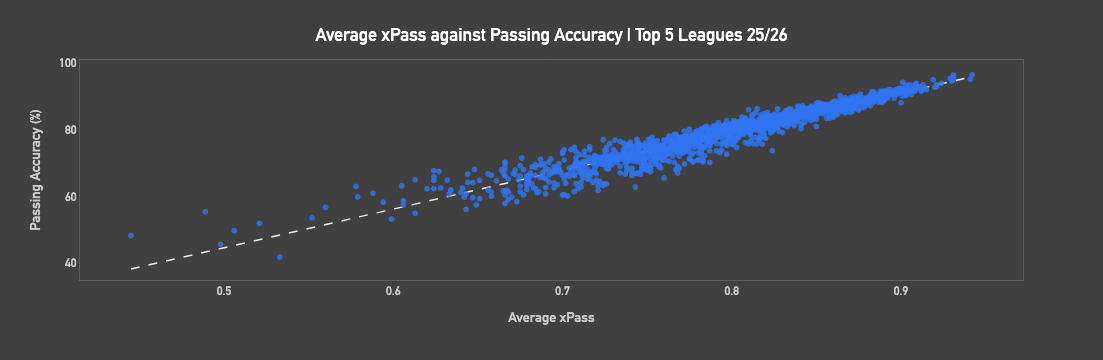

In [144]:
import plotly.express as px
import numpy as np
from scipy.stats import linregress

plot_data = player_season_xpass[player_season_xpass["matches_played"] >= 20][["player", 
                                                                              "avg_xPass", 
                                                                              "passing_acc", 
                                                                              "PAx_per_100"]].dropna().copy()

plot_data["avg_xPass"] = plot_data["avg_xPass"].round(3)
plot_data["passing_acc"] = plot_data["passing_acc"].round(3)
plot_data["PAx_per_100"] = plot_data["PAx_per_100"].round(3)


# Regression statistics
x = plot_data["avg_xPass"]
y = plot_data["passing_acc"]

regression = linregress(x, y)
r = regression.rvalue
r_squared = r ** 2
p = regression.pvalue

print(f"Correlation (r): {r:.3f}")
print(f"R²: {r_squared:.3f}")
print(f"p-value: {p:.3e}")

fig = px.scatter(
    plot_data,
    x="avg_xPass",
    y="passing_acc",
    color_discrete_sequence=["#3074F2"],    
    custom_data=["avg_xPass",
                 "passing_acc",
                 "PAx_per_100"],
    
    hover_name="player",
    hover_data={
        "player": False,
        "avg_xPass": ":.3f",
        "passing_acc" : ":.3f",
        "PAx_per_100" : ":.3f"
    },
    labels={
    "avg_xPass": "Average xPass",
    "passing_acc": "Passing accuracy (%)",
    "PAx_per_100": "PAx per 100 passes"},
    
    trendline="ols",
    trendline_scope = "overall",
    opacity=0.8)

fig.update_traces(
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "Average xPass: %{customdata[0]:.2f}<br>"
        "Passing Accuracy: %{customdata[1]:.2f}%<br>"
        "PAx per 100 passes: %{customdata[2]:.2f}<br>"
        "<extra></extra>"
    ),
    selector=dict(mode="markers")
)


fig.update_traces(
    line=dict(
        color="#fff", 
        width=1.5,          
        dash="dash"       
    ),
    opacity=0.9,
    selector=dict(mode="lines"),
    showlegend = False
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    title={
        "text": "Average xPass against Passing Accuracy | Top 5 Leagues 25/26",
        "x": 0.5,
        "xanchor": "center",
        "y": 0.92,
        "font": {
            "family": "DIN Alternate",
            "size": 18,
            "color": "#FFFFFF"
        }
    },
    font={
        "family": "DIN Alternate",
        "size": 12,
        "color": "#CCCCCC"
    },
    xaxis_title="Average xPass",
    yaxis_title="Passing Accuracy (%)",

    xaxis={
        "showgrid": False,
        "gridcolor": "#616060",
        "gridwidth": 1,
        "zeroline": False,
        "mirror" : True,
        "showline": True,
        "linecolor": "#616060"
    },
    yaxis={
        "showgrid": False,
        "gridcolor": "#616060",
        "gridwidth": 1,
        "zeroline": False,
        "mirror" : True,
        "showline": True,
        "linecolor": "#616060"
    },

    height=None,
    autosize = True
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/xPass_passing_accuracy.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})


### Average xPass against PAx per 100 passes

Correlation (r): 0.412
R²: 0.170
p-value: 1.223e-62


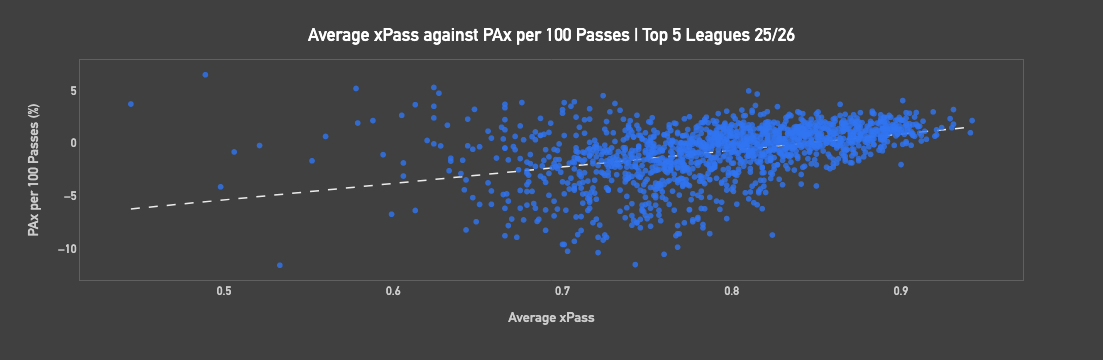

In [168]:
import plotly.express as px
import numpy as np
from scipy.stats import linregress

plot_data = player_season_xpass[player_season_xpass["matches_played"] >= 20][["player", 
                                                                              "avg_xPass", 
                                                                              "passing_acc", 
                                                                              "PAx_per_100"]].dropna().copy()

plot_data["avg_xPass"] = plot_data["avg_xPass"].round(3)
plot_data["passing_acc"] = plot_data["passing_acc"].round(3)
plot_data["PAx_per_100"] = plot_data["PAx_per_100"].round(3)


# Regression statistics
x = plot_data["avg_xPass"]
y = plot_data["PAx_per_100"]

regression = linregress(x, y)
r = regression.rvalue
r_squared = r ** 2
p = regression.pvalue

print(f"Correlation (r): {r:.3f}")
print(f"R²: {r_squared:.3f}")
print(f"p-value: {p:.3e}")

fig = px.scatter(
    plot_data,
    x="avg_xPass",
    y="PAx_per_100",
    color_discrete_sequence=["#3074F2"],    
    custom_data=["avg_xPass",
                 "PAx_per_100",
                 "passing_acc"],
    
    hover_name="player",
    hover_data={
        "player": False,
        "avg_xPass": ":.3f",
        "PAx_per_100" : ":.3f",
        "passing_acc" : ":.3f"},
    
    labels={
    "avg_xPass": "Average xPass",
    "PAx_per_100": "PAx per 100 passes",
    "passing_acc": "Passing accuracy (%)"},
    
    trendline="ols",
    trendline_scope = "overall",
    opacity=0.8)

fig.update_traces(
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "Average xPass: %{customdata[0]:.2f}<br>"
        "PAx per 100 passes: %{customdata[1]:.2f}<br>"
        "Passing Accuracy: %{customdata[2]:.2f}%<br>"
        "<extra></extra>"
    ),
    selector=dict(mode="markers")
)


fig.update_traces(
    line=dict(
        color="#fff", 
        width=1.5,          
        dash="dash"       
    ),
    opacity=0.9,
    selector=dict(mode="lines"),
    showlegend = False
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    title={
        "text": "Average xPass against PAx per 100 Passes | Top 5 Leagues 25/26",
        "x": 0.5,
        "xanchor": "center",
        "y": 0.92,
        "font": {
            "family": "DIN Alternate",
            "size": 18,
            "color": "#FFFFFF"
        }
    },
    font={
        "family": "DIN Alternate",
        "size": 12,
        "color": "#CCCCCC"
    },
    xaxis_title="Average xPass",
    yaxis_title="PAx per 100 Passes (%)",

    xaxis={
        "showgrid": False,
        "gridcolor": "#616060",
        "gridwidth": 1,
        "zeroline": False,
        "mirror" : True,
        "showline": True,
        "linecolor": "#616060"
    },
    yaxis={
        "showgrid": False,
        "gridcolor": "#616060",
        "gridwidth": 1,
        "zeroline": False,
        "mirror" : True,
        "showline": True,
        "linecolor": "#616060"
    },

    height=None,
    autosize = True
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/xPass_PAx_per_100.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})


### Average xPass vs xT per pass

Correlation (r): -0.539
R²: 0.291
p-value: 1.911e-32


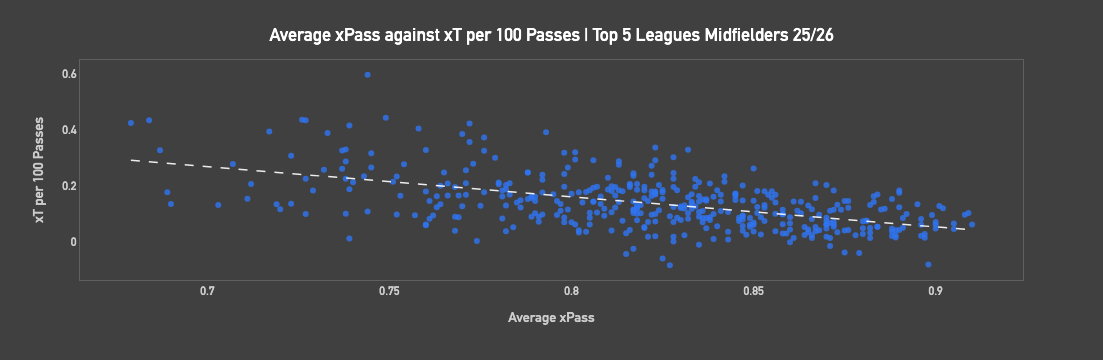

In [166]:
import plotly.express as px
import numpy as np
from scipy.stats import linregress

plot_data = midfielders_df[midfielders_df["matches_played"] >= 20][["name", 
                                                                    "avg_xPass", 
                                                                    "xT_per_100_passes", 
                                                                    "PAx_per_100",
                                                                    "passing_acc"]].dropna().copy()

plot_data["avg_xPass"] = plot_data["avg_xPass"].round(3)
plot_data["xT_per_100_passes"] = plot_data["xT_per_100_passes"].round(3)
plot_data["PAx_per_100"] = plot_data["PAx_per_100"].round(3)
plot_data["passing_acc"] = plot_data["passing_acc"].round(3)

# Regression statistics
x = plot_data["avg_xPass"]
y = plot_data["xT_per_100_passes"]

regression = linregress(x, y)
r = regression.rvalue
r_squared = r ** 2
p = regression.pvalue

print(f"Correlation (r): {r:.3f}")
print(f"R²: {r_squared:.3f}")
print(f"p-value: {p:.3e}")

fig = px.scatter(
    plot_data,
    x="avg_xPass",
    y="xT_per_100_passes",
    color_discrete_sequence=["#3074F2"],    
    custom_data=["avg_xPass",
                 "xT_per_100_passes",
                 "PAx_per_100",
                 "passing_acc"],
    
    hover_name="name",
    hover_data={
        "name": False,
        "avg_xPass": ":.3f",
        "xT_per_100_passes": ":.3f",
        "PAx_per_100" : ":.3f",
        "passing_acc" : ":.3f"},
    
    labels={
    "avg_xPass": "Average xPass",
    "xT_per_100_passes" : "xT per 100 passes",
    "PAx_per_100": "PAx per 100 passes",
    "passing_acc": "Passing accuracy (%)"},
    
    trendline="ols",
    trendline_scope = "overall",
    opacity=0.8)

fig.update_traces(
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "Average xPass: %{customdata[0]:.2f}<br>"
        "xT per 100 Passes: %{customdata[1]:.2f}<br>"
        "PAx per 100 Passes: %{customdata[2]:.2f}<br>"
        "Passing Accuracy: %{customdata[3]:.2f}%<br>"
        "<extra></extra>"
    ),
    selector=dict(mode="markers")
)


fig.update_traces(
    line=dict(
        color="#fff", 
        width=1.5,          
        dash="dash"       
    ),
    opacity=0.9,
    selector=dict(mode="lines"),
    showlegend = False
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    title={
        "text": "Average xPass against xT per 100 Passes | Top 5 Leagues Midfielders 25/26",
        "x": 0.5,
        "xanchor": "center",
        "y": 0.92,
        "font": {
            "family": "DIN Alternate",
            "size": 18,
            "color": "#FFFFFF"
        }
    },
    font={
        "family": "DIN Alternate",
        "size": 12,
        "color": "#CCCCCC"
    },
    xaxis_title="Average xPass",
    yaxis_title="xT per 100 Passes",

    xaxis={
        "showgrid": False,
        "gridcolor": "#616060",
        "gridwidth": 1,
        "zeroline": False,
        "mirror" : True,
        "showline": True,
        "linecolor": "#616060"
    },
    yaxis={
        "showgrid": False,
        "gridcolor": "#616060",
        "gridwidth": 1,
        "zeroline": False,
        "mirror" : True,
        "showline": True,
        "linecolor": "#616060"
    },

    height=None,
    autosize = True
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/xPass_xT_per_100.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})


### PAx per 100 passes vs xT per 100 passes

Correlation (r): -0.042
R²: 0.002
p-value: 3.953e-01


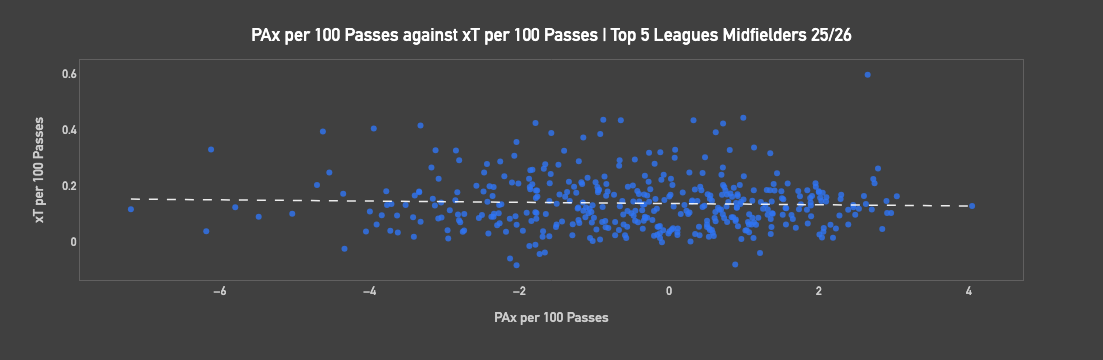

In [172]:
import plotly.express as px
import numpy as np
from scipy.stats import linregress

plot_data = midfielders_df[midfielders_df["matches_played"] >= 20][["name", 
                                                                    "avg_xPass", 
                                                                    "xT_per_100_passes", 
                                                                    "PAx_per_100",
                                                                    "passing_acc"]].dropna().copy()

plot_data["avg_xPass"] = plot_data["avg_xPass"].round(3)
plot_data["xT_per_100_passes"] = plot_data["xT_per_100_passes"].round(3)
plot_data["PAx_per_100"] = plot_data["PAx_per_100"].round(3)
plot_data["passing_acc"] = plot_data["passing_acc"].round(3)

# Regression statistics
x = plot_data["PAx_per_100"]
y = plot_data["xT_per_100_passes"]

regression = linregress(x, y)
r = regression.rvalue
r_squared = r ** 2
p = regression.pvalue

print(f"Correlation (r): {r:.3f}")
print(f"R²: {r_squared:.3f}")
print(f"p-value: {p:.3e}")

fig = px.scatter(
    plot_data,
    x="PAx_per_100",
    y="xT_per_100_passes",
    color_discrete_sequence=["#3074F2"],    
    custom_data=["PAx_per_100",
                 "xT_per_100_passes",
                 "avg_xPass",
                 "passing_acc"],
    
    hover_name="name",
    hover_data={
        "name": False,
        "PAx_per_100": ":.3f",
        "xT_per_100_passes": ":.3f",
        "avg_xPass" : ":.3f",
        "passing_acc" : ":.3f"},
    
    labels={
    "avg_xPass": "Average xPass",
    "xT_per_100_passes" : "xT per 100 passes",
    "PAx_per_100": "PAx per 100 passes",
    "passing_acc": "Passing accuracy (%)"},
    
    trendline="ols",
    trendline_scope = "overall",
    opacity=0.8)

fig.update_traces(
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "PAx per 100 Passes: %{customdata[0]:.2f}<br>"
        "xT per 100 Passes: %{customdata[1]:.2f}<br>"
        "Average xPass: %{customdata[2]:.2f}<br>"
        "Passing Accuracy: %{customdata[3]:.2f}%<br>"
        "<extra></extra>"
    ),
    selector=dict(mode="markers")
)


fig.update_traces(
    line=dict(
        color="#fff", 
        width=1.5,          
        dash="dash"       
    ),
    opacity=0.9,
    selector=dict(mode="lines"),
    showlegend = False
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    title={
        "text": "PAx per 100 Passes against xT per 100 Passes | Top 5 Leagues Midfielders 25/26",
        "x": 0.5,
        "xanchor": "center",
        "y": 0.92,
        "font": {
            "family": "DIN Alternate",
            "size": 18,
            "color": "#FFFFFF"
        }
    },
    font={
        "family": "DIN Alternate",
        "size": 12,
        "color": "#CCCCCC"
    },
    xaxis_title="PAx per 100 Passes",
    yaxis_title="xT per 100 Passes",

    xaxis={
        "showgrid": False,
        "gridcolor": "#616060",
        "gridwidth": 1,
        "zeroline": False,
        "mirror" : True,
        "showline": True,
        "linecolor": "#616060"
    },
    yaxis={
        "showgrid": False,
        "gridcolor": "#616060",
        "gridwidth": 1,
        "zeroline": False,
        "mirror" : True,
        "showline": True,
        "linecolor": "#616060"
    },

    height=None,
    autosize = True
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/PAx_per_100_xT_per_100.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})


### Top and bottom average xPassers

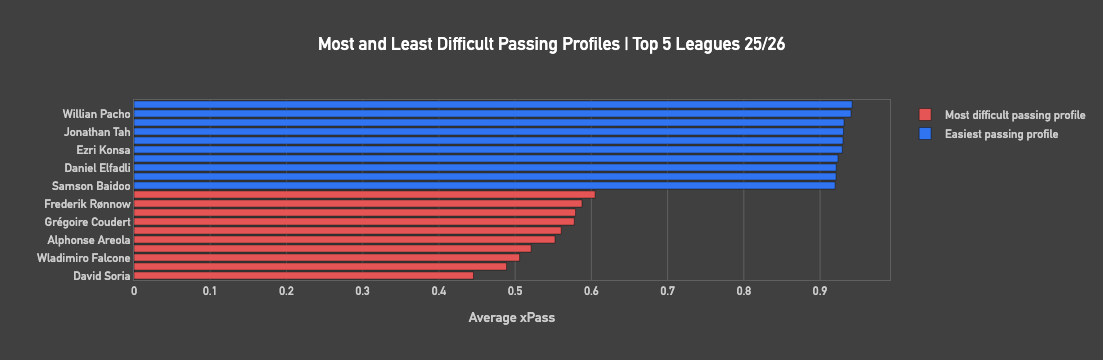

In [232]:
import plotly.express as px
import pandas as pd

# Filter players
eligible = player_season_xpass[
    (player_season_xpass["matches_played"] >= 20) &
    (player_season_xpass["attempted_passes"] >= 500)
].copy()

# Top and bottom 10
top_10 = eligible.nlargest(10, "avg_xPass").copy()
top_10["group"] = "Easiest passing profile"

bottom_10 = eligible.nsmallest(10, "avg_xPass").copy()
bottom_10["group"] = "Most difficult passing profile"

# Combine and sort
plot_data = pd.concat([top_10, bottom_10])
plot_data = plot_data.sort_values("avg_xPass", ascending=True)

fig = px.bar(
    plot_data,
    x="avg_xPass",
    y="player",
    orientation="h",
    color="group",
    color_discrete_map={
        "Easiest passing profile": "#3074F2",
        "Most difficult passing profile": "#E65555"
    },
    custom_data=["attempted_passes", "passing_acc"],
    labels={
        "avg_xPass": "Average xPass",
        "player": "",
        "passing_acc" : "Passing Accuracy",
        "group": "Passing profile"
    },
    title="Most and Least Difficult Passing Profiles | Top 5 Leagues 25/26"
)

fig.update_traces(
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Average xPass: %{x:.3f}<br>"
        "Attempted passes: %{customdata[0]}<br>"
        "Passing Accuracy: %{customdata[1]:.2f}%<br>"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    font=dict(family="DIN Alternate", size=12, color="#CCCCCC"),
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=18, color="#FFFFFF")
    ),
    xaxis=dict(
        title="Average xPass",
        showgrid=True,
        gridcolor ="#616060",
        gridwidth = 1,
        showline=True,
        mirror=True,
        linecolor="#616060"
    ),
    yaxis=dict(
        title="",
        showgrid=False,
        showline=True,
        mirror=True,
        linecolor="#616060"
    ),
    legend_title_text="",
    height=None, 
    autosize = True
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/difficult_v_easy_xPass_profiles.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})

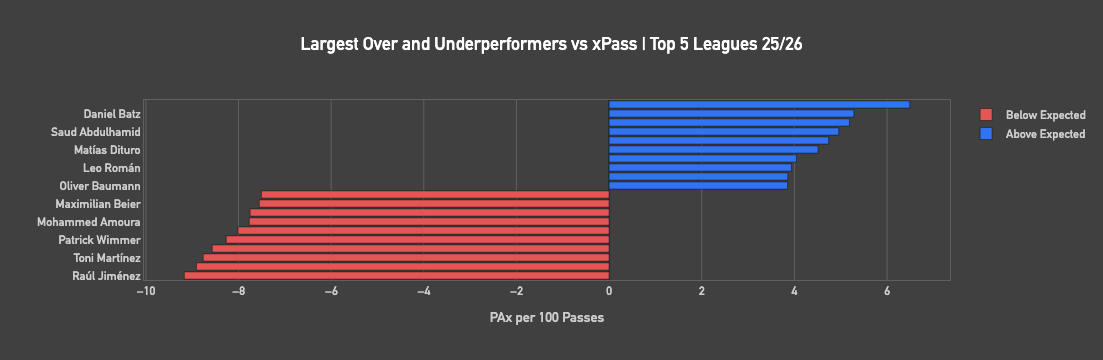

In [222]:
import plotly.express as px
import pandas as pd

# Filter players
eligible = player_season_xpass[
    (player_season_xpass["matches_played"] >= 20) &
    (player_season_xpass["attempted_passes"] >= 500)
].copy()

# Top and bottom 10
top_10 = eligible.nlargest(10, "PAx_per_100").copy()
top_10["group"] = "Above Expected"

bottom_10 = eligible.nsmallest(10, "PAx_per_100").copy()
bottom_10["group"] = "Below Expected"

# Combine and sort
plot_data = pd.concat([top_10, bottom_10])
plot_data = plot_data.sort_values("PAx_per_100", ascending=True)

fig = px.bar(
    plot_data,
    x="PAx_per_100",
    y="player",
    orientation="h",
    color="group",
    color_discrete_map={
        "Above Expected": "#3074F2",
        "Below Expected": "#E65555"
    },
    custom_data=["attempted_passes", "passing_acc"],
    labels={
        "PAx_per_100": "PAx per 100 Passes",
        "player": "",
        "passing_acc" : "Passing Accuracy",
        "group": "Passing profile"
    },
    title="Largest Over and Underperformers vs xPass | Top 5 Leagues 25/26"
)

fig.update_traces(
    hovertemplate=(
        "<b>%{y}</b><br>"
        "PAx per 100 Passes: %{x:.3f}<br>"
        "Attempted passes: %{customdata[0]}<br>"
        "Passing Accuracy: %{customdata[1]:.2f}%<br>"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    font=dict(family="DIN Alternate", size=12, color="#CCCCCC"),
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=18, color="#FFFFFF")
    ),
    xaxis=dict(
        title="PAx per 100 Passes",
        showgrid=True,
        gridcolor ="#616060",
        gridwidth = 1,
        showline=True,
        mirror=True,
        linecolor="#616060"
    ),
    yaxis=dict(
        title="",
        showgrid=False,
        showline=True,
        mirror=True,
        linecolor="#616060"
    ),
    legend_title_text="",
    height=None, 
    autosize = True
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/under_overperformers.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})

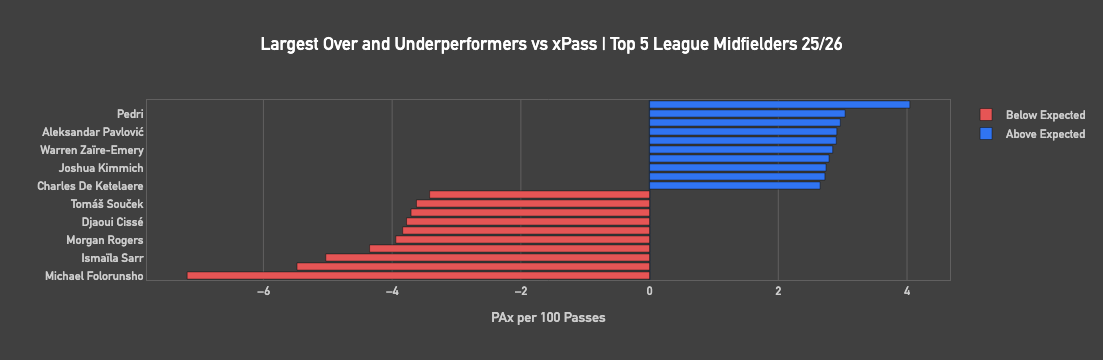

In [224]:
import plotly.express as px
import pandas as pd

# Filter players
eligible = midfielders_df[
    (midfielders_df["matches_played"] >= 20) &
    (midfielders_df["attempted_passes"] >= 500)
].copy()

# Top and bottom 10
top_10 = eligible.nlargest(10, "PAx_per_100").copy()
top_10["group"] = "Above Expected"

bottom_10 = eligible.nsmallest(10, "PAx_per_100").copy()
bottom_10["group"] = "Below Expected"

# Combine and sort
plot_data = pd.concat([top_10, bottom_10])
plot_data = plot_data.sort_values("PAx_per_100", ascending=True)

fig = px.bar(
    plot_data,
    x="PAx_per_100",
    y="name",
    orientation="h",
    color="group",
    color_discrete_map={
        "Above Expected": "#3074F2",
        "Below Expected": "#E65555"
    },
    custom_data=["attempted_passes", "passing_acc"],
    labels={
        "PAx_per_100": "PAx per 100 Passes",
        "player": "",
        "passing_acc" : "Passing Accuracy",
        "group": "Passing profile"
    },
    title="Largest Over and Underperformers vs xPass | Top 5 League Midfielders 25/26"
)

fig.update_traces(
    hovertemplate=(
        "<b>%{y}</b><br>"
        "PAx per 100 Passes: %{x:.3f}<br>"
        "Attempted passes: %{customdata[0]}<br>"
        "Passing Accuracy: %{customdata[1]:.2f}%<br>"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    font=dict(family="DIN Alternate", size=12, color="#CCCCCC"),
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=18, color="#FFFFFF")
    ),
    xaxis=dict(
        title="PAx per 100 Passes",
        showgrid=True,
        gridcolor ="#616060",
        gridwidth = 1,
        showline=True,
        mirror=True,
        linecolor="#616060"
    ),
    yaxis=dict(
        title="",
        showgrid=False,
        showline=True,
        mirror=True,
        linecolor="#616060"
    ),
    legend_title_text="",
    height=None, 
    autosize = True
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/under_overperformers_mids.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})

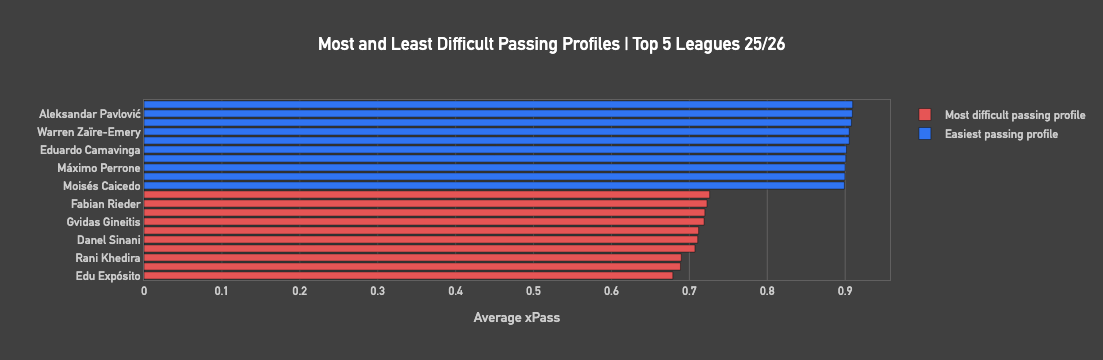

In [226]:
import plotly.express as px
import pandas as pd

# Filter players
eligible = midfielders_df[
    (midfielders_df["matches_played"] >= 20) &
    (midfielders_df["attempted_passes"] >= 500)
].copy()

# Top and bottom 10
top_10 = eligible.nlargest(10, "avg_xPass").copy()
top_10["group"] = "Easiest passing profile"

bottom_10 = eligible.nsmallest(10, "avg_xPass").copy()
bottom_10["group"] = "Most difficult passing profile"

# Combine and sort
plot_data = pd.concat([top_10, bottom_10])
plot_data = plot_data.sort_values("avg_xPass", ascending=True)

fig = px.bar(
    plot_data,
    x="avg_xPass",
    y="name",
    orientation="h",
    color="group",
    color_discrete_map={
        "Easiest passing profile": "#3074F2",
        "Most difficult passing profile": "#E65555"
    },
    custom_data=["attempted_passes", "passing_acc"],
    labels={
        "avg_xPass": "Average xPass",
        "player": "",
        "passing_acc" : "Passing Accuracy",
        "group": "Passing profile"
    },
    title="Most and Least Difficult Passing Profiles | Top 5 Leagues 25/26"
)

fig.update_traces(
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Average xPass: %{x:.3f}<br>"
        "Attempted passes: %{customdata[0]}<br>"
        "Passing Accuracy: %{customdata[1]:.2f}%<br>"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#404040",
    plot_bgcolor="#404040",
    font=dict(family="DIN Alternate", size=12, color="#CCCCCC"),
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=18, color="#FFFFFF")
    ),
    xaxis=dict(
        title="Average xPass",
        showgrid=True,
        gridcolor ="#616060",
        gridwidth = 1,
        showline=True,
        mirror=True,
        linecolor="#616060"
    ),
    yaxis=dict(
        title="",
        showgrid=False,
        showline=True,
        mirror=True,
        linecolor="#616060"
    ),
    legend_title_text="",
    height=None, 
    autosize = True
)

fig.show()

fig.write_html(Path.cwd().parent / "figures/difficult_v_easy_xPass_profiles_mids.html",
              config = {"responsive" : True,
                        "displayModeBar" : False})